Running the 10-year hourly model... (about 15 seconds)


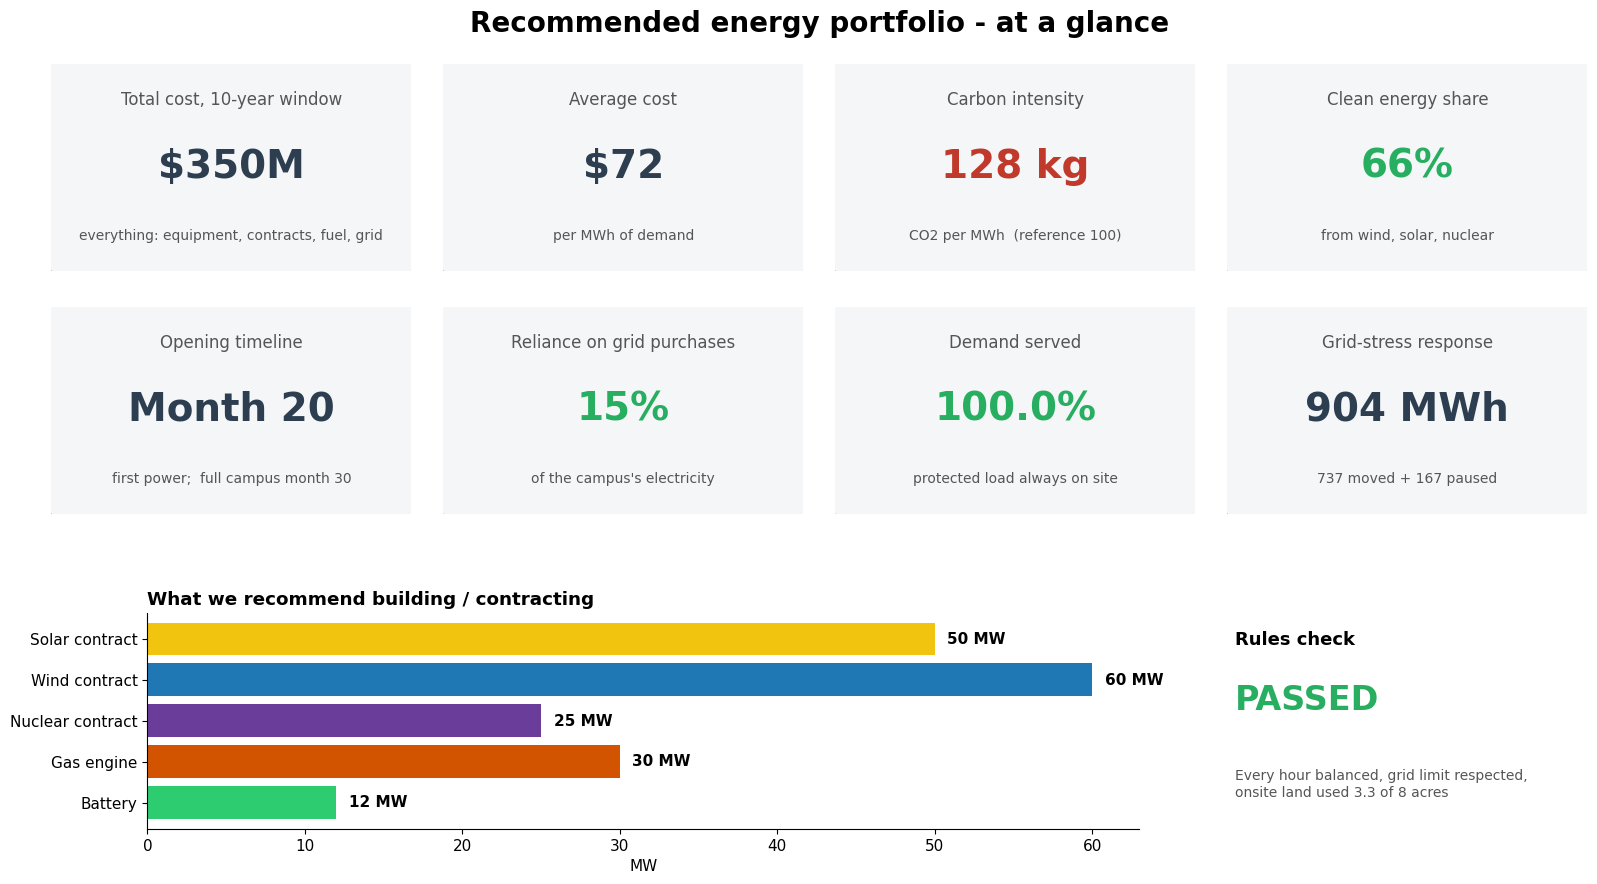

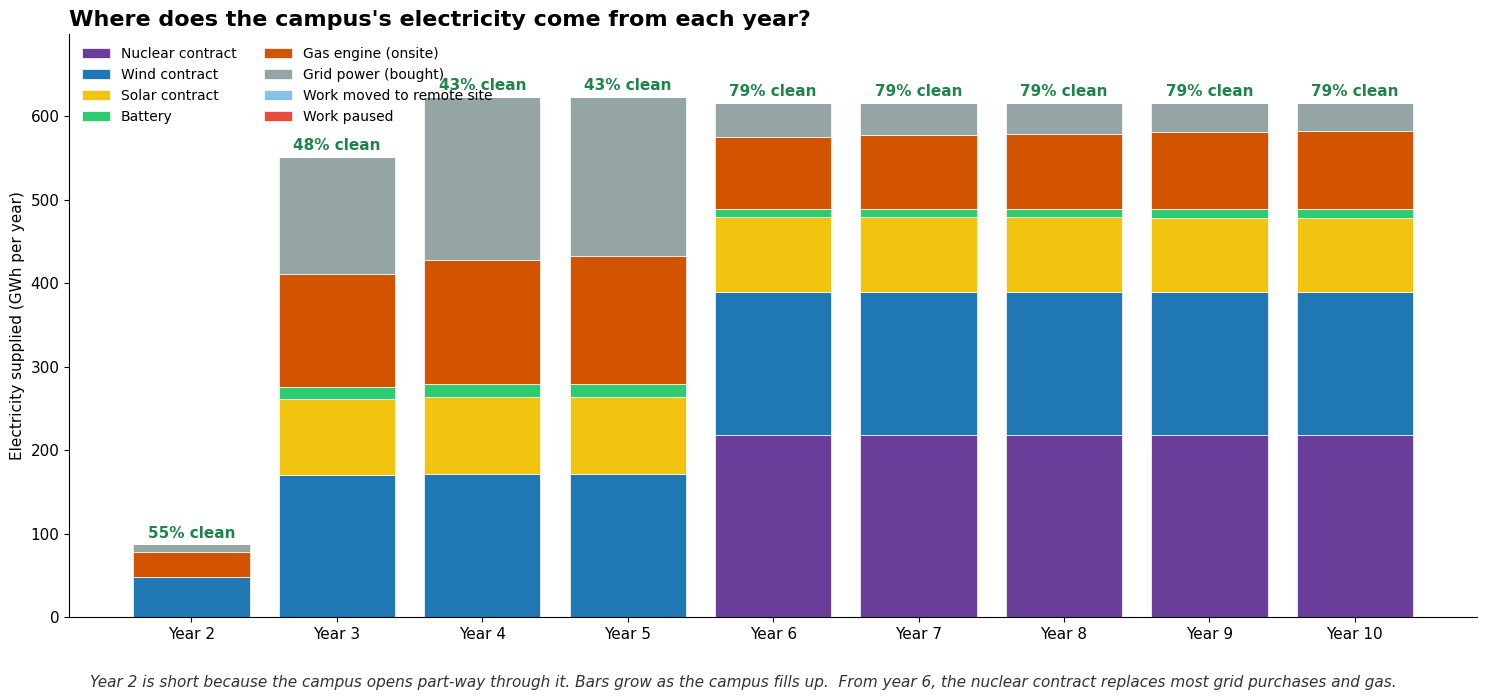

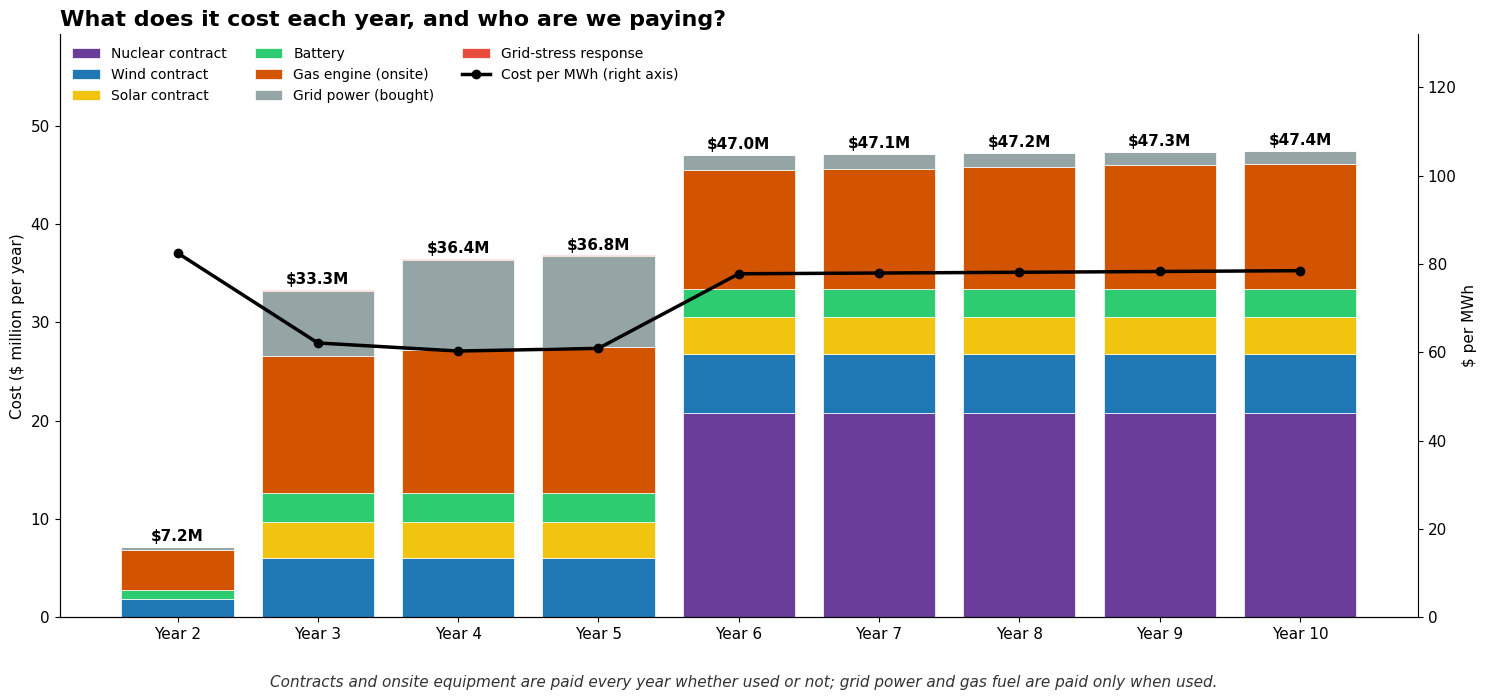

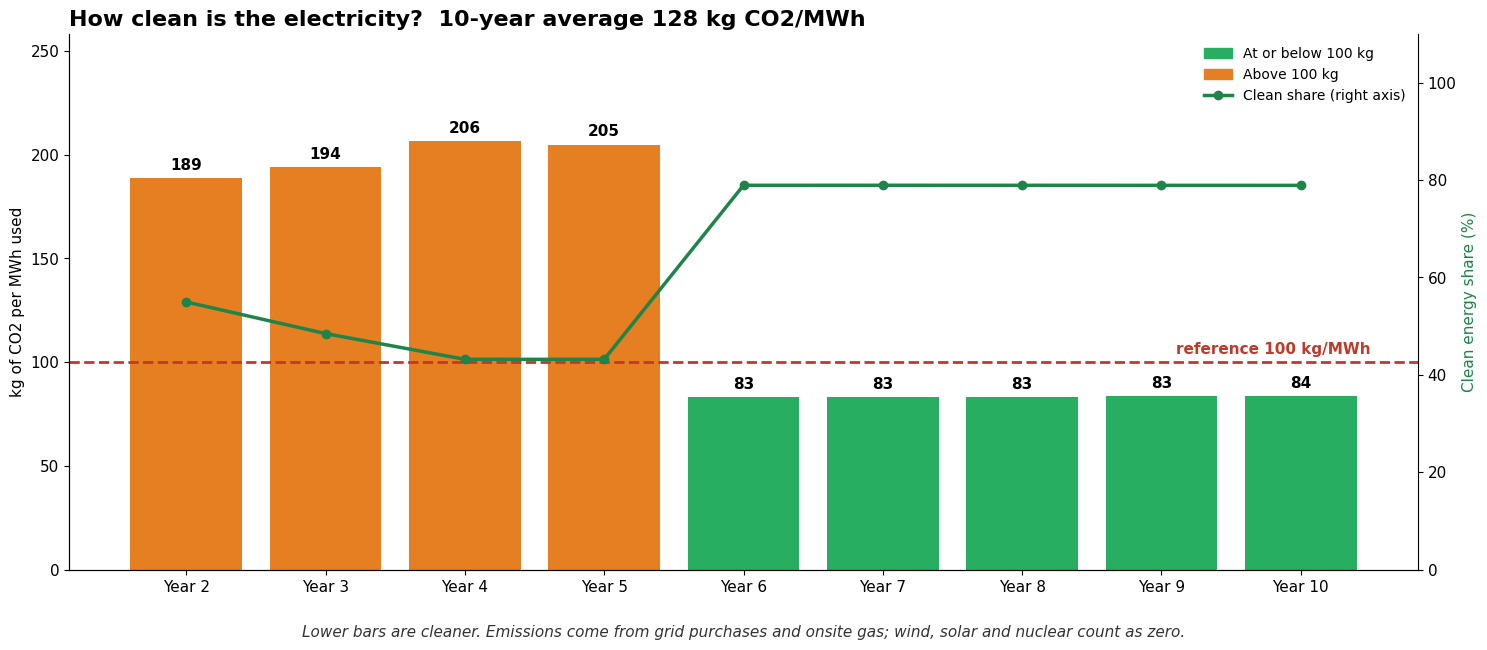

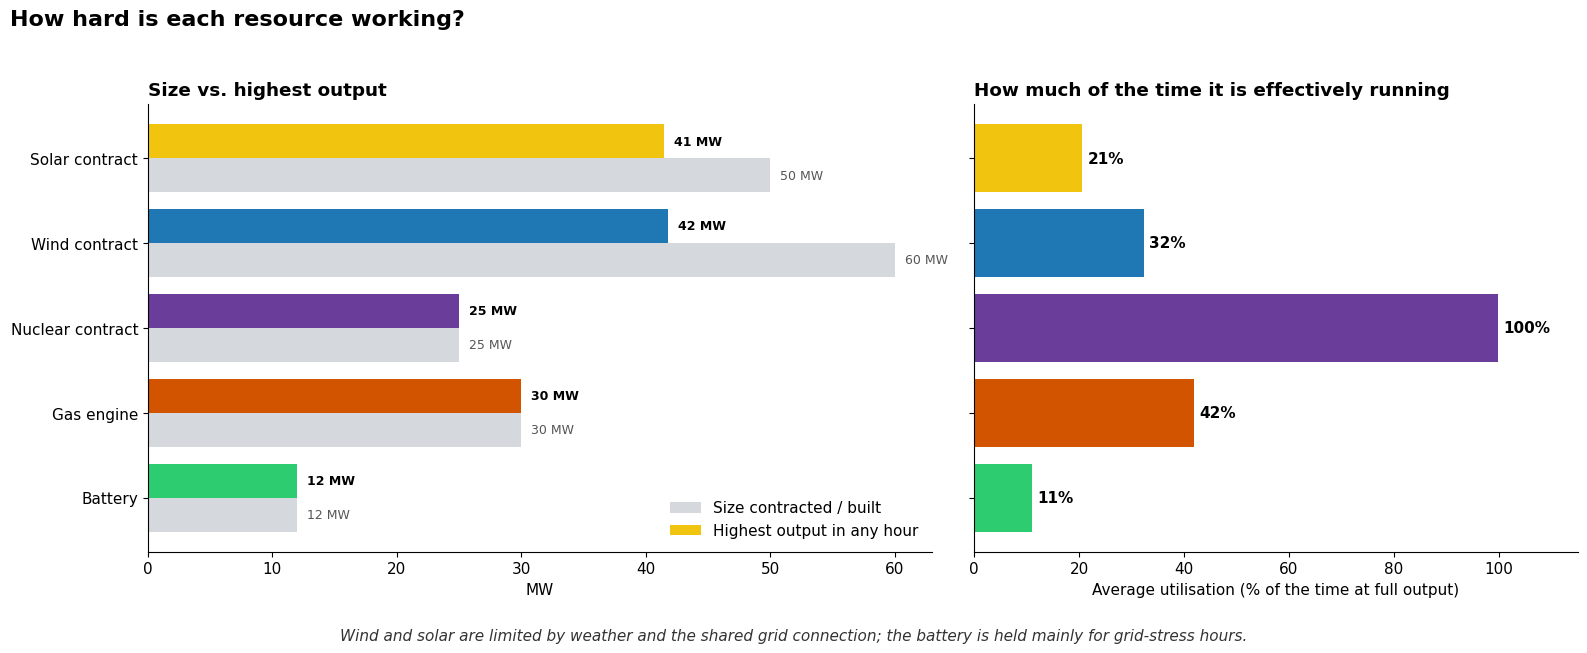

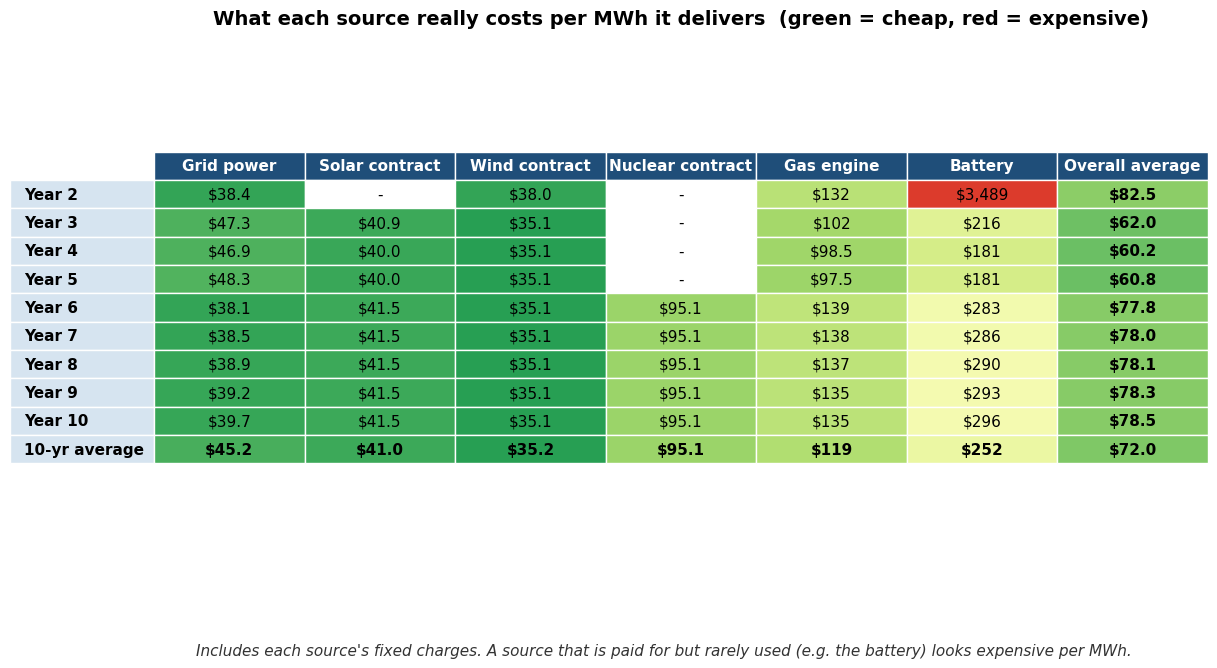

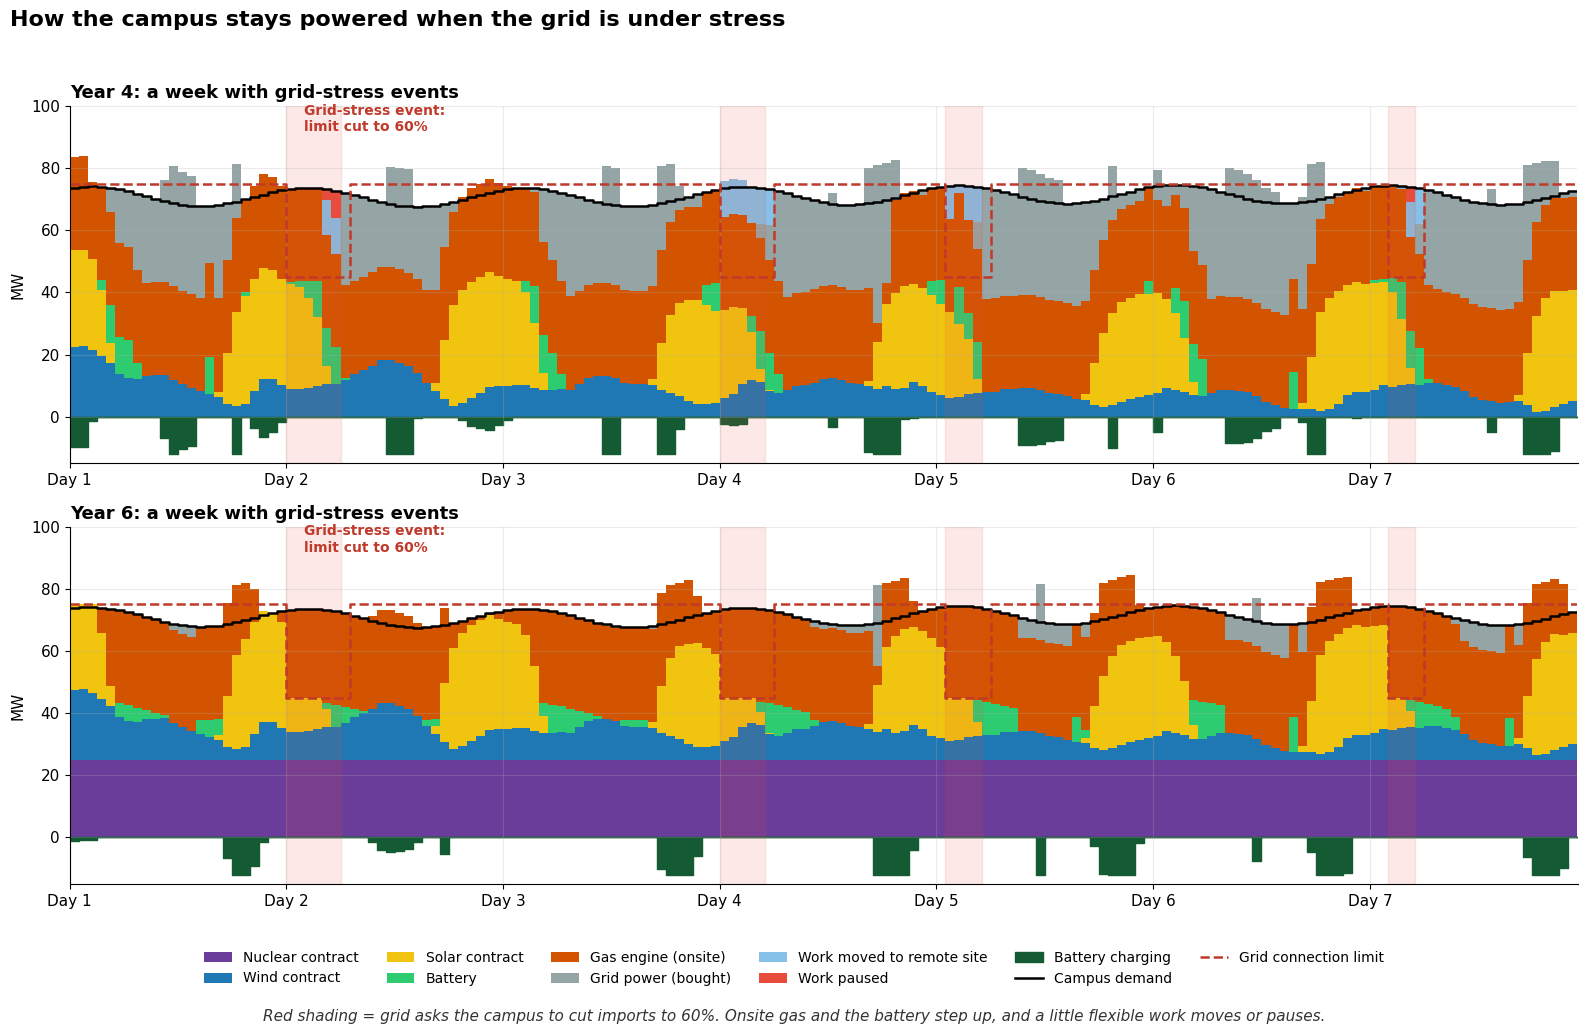

Done. 7 visuals saved to C:\Users\shara\Downloads\outputs\visuals
Submission files (dispatch.csv, portfolio.json) saved to C:\Users\shara\Downloads\outputs


In [2]:
"""
GRIDTECH - yearly dispatch engine + runner in ONE file.

Jupyter: paste into a cell, or save as gridtech_all.py and `%run gridtech_all.py`.
Edit DATA_DIR / INITIAL_SERVICE_MONTH / CAPS in the "EDIT HERE" block near the bottom.
"""
# GRIDTECH yearly dispatch engine.
# 
# For a FIXED portfolio (capacities chosen upfront for the whole horizon), solve one
# hourly dispatch LP per model year (10 x 8,760 h) with HiGHS via scipy.linprog,
# stitch the years into the 87,600-hour dispatch.csv, and compute common accounting.
# 
# Year decomposition assumption: battery SOC is forced to 0 at the end of every
# model year (and so starts each year at 0). The rules only require SOC=0 at hour 0
# and at the final hour, so this is a conservative restriction - every schedule it
# produces is still valid under the common rules, it just leaves a little
# cross-year storage value on the table (negligible for a 4-hour battery).

from pathlib import Path
import numpy as np
import pandas as pd
import scipy.sparse as sp
from scipy.optimize import linprog

# ---------------------------------------------------------------- constants
HPY, HPM, HORIZON_H = 8760, 730, 87600
ETA = np.sqrt(0.85)                         # one-way battery efficiency
REMOTE_MW_LOCAL = 12.0 / 1.05               # local-equivalent relocation cap
RELOC_USD, INTERRUPT_USD = 1.05 * 70 + 50, 1000.0
REMOTE_CO2_0 = 0.33287420383294             # t/MWh at model_hour 0
RATE_WHOLESALE, RATE_HH, RATE_CO2 = 0.05, 0.03, -0.03
CRF_R = 0.08
UNSERVED_PENALTY = 1e5                      # $/MWh slack: flags an inadequate portfolio
EPS = 1e-3                                  # tiny battery throughput cost -> no simultaneous ch/dis
GRID_SCHEDULE = [(0, 0), (18, 25), (24, 50), (30, 75)]
LAND_ACRES = 8.0

RES_ORDER = ["utility_solar", "wind", "nuclear", "gas_turbine", "gas_engine", "fuel_cell", "battery_4h"]
GAS = ["gas_turbine", "gas_engine", "fuel_cell"]
CLEAN = ["utility_solar", "wind", "nuclear"]
OFFSITE = CLEAN
PROFILE = {"utility_solar": "solar_proxy_cf", "wind": "wind_proxy_cf",
           "nuclear": "firm_clean_available_fraction"}

# LP variable blocks (each block has n = hours-in-year entries)
VARS = ["grid", "utility_solar", "wind", "nuclear", "gas_turbine", "gas_engine",
        "fuel_cell", "ch", "dis", "soc", "reloc", "curt", "unserved"]
IDX = {v: i for i, v in enumerate(VARS)}


# ---------------------------------------------------------------- inputs
def load_resources(data_dir):
    r = pd.read_csv(Path(data_dir) / "resource_options.csv").set_index("option_id")
    return r


def build_timeline(data_dir, initial_service_month=20, grid_delay_months=0):
    """Expand reference_hourly.csv to 87,600 h for any opening month (MODEL_RULES s1, s2, s5)."""
    ref = pd.read_csv(Path(data_dir) / "reference_hourly.csv")
    h = np.arange(HORIZON_H)
    rh = h % HPY
    month = h // HPM
    R = ref.iloc[rh].reset_index(drop=True)

    k = month - initial_service_month
    frac = np.where(k < 0, 0.0, np.minimum(1.0, 1 / 3 + k / 15))

    cap = np.zeros(HORIZON_H)
    for m0, mw in GRID_SCHEDULE:
        start = m0 + (grid_delay_months if mw > 0 else 0)
        cap[month >= start] = mw

    yrs = h / HPY
    t = pd.DataFrame({
        "model_hour": h, "development_month": month, "model_year": h // HPY + 1,
        "reference_hour": rh, "demand_fraction": frac,
        "load_mw": R.load_mw * frac,
        "tier0_protected_mw": R.tier0_protected_mw * frac,
        "tier1_relocatable_mw": R.tier1_relocatable_mw * frac,
        "tier2_interruptible_mw": R.tier2_interruptible_mw * frac,
        "ordinary_grid_limit_mw": cap,
        "effective_grid_limit_mw": cap * R.stress_import_fraction,
        "stress_active": R.stress_active,
        "wind_proxy_cf": R.wind_proxy_cf, "solar_proxy_cf": R.solar_proxy_cf,
        "firm_clean_available_fraction": R.firm_clean_available_fraction,
        "grid_co2_t_per_mwh": R.grid_co2_t_per_mwh * (1 + RATE_CO2) ** yrs,
        "merchant_price_usd_per_mwh": R.wholesale_price_usd_per_mwh * (1 + RATE_WHOLESALE) ** yrs
                                      + R.grid_adder_usd_per_mwh,
        "delivered_gas_price_usd_per_mmbtu": R.henry_hub_usd_per_mmbtu * (1 + RATE_HH) ** yrs
                                             + R.delivered_gas_adder_usd_per_mmbtu,
    })
    return t


def availability(res, caps, t, start_month):
    """1/0 mask per resource: on from max(initial_service_month, available_month)."""
    mon = t.development_month.values
    return {r: ((mon >= max(start_month, res.loc[r, "available_month"])) & (caps.get(r, 0) > 0)).astype(float)
            for r in RES_ORDER}


def check_portfolio(res, caps):
    for r, mw in caps.items():
        b, mx = res.loc[r, "block_mw"], res.loc[r, "max_mw"]
        assert mw >= 0 and mw <= mx and abs(mw / b - round(mw / b)) < 1e-9, f"{r}: {mw} MW breaks block/max"
    land = sum(mw * res.loc[r, "land_acres_per_mw"] for r, mw in caps.items())
    assert land <= LAND_ACRES + 1e-9, f"land {land:.2f} acres > 8"
    return land


# ---------------------------------------------------------------- one-year LP
def solve_year(t_year, res, caps, avail_year, zero_tier2=False):
    """Hourly dispatch LP for one model year. Returns DataFrame of dispatch + status."""
    n = len(t_year)
    nv = len(VARS) * n
    col = lambda v: IDX[v] * n + np.arange(n)
    I = np.arange(n)

    load = t_year.load_mw.values
    stress = t_year.stress_active.values.astype(bool)
    gp = t_year.delivered_gas_price_usd_per_mmbtu.values
    mw_b = caps.get("battery_4h", 0)

    # ---- objective (only avoidable / variable costs; contract & capacity charges are sunk)
    c = np.zeros(nv)
    c[col("grid")] = t_year.merchant_price_usd_per_mwh.values
    for g in GAS:
        c[col(g)] = res.loc[g, "payment_usd_per_mwh"] + res.loc[g, "heat_rate_mmbtu_per_mwh_hhv"] * gp
    c[col("ch")] = EPS
    c[col("dis")] = EPS
    c[col("reloc")] = RELOC_USD
    c[col("curt")] = INTERRUPT_USD
    c[col("unserved")] = UNSERVED_PENALTY

    # ---- bounds
    lb, ub = np.zeros(nv), np.zeros(nv)
    ub[col("grid")] = np.inf                                     # capped by import row below
    for r in CLEAN:
        ub[col(r)] = caps.get(r, 0) * t_year[PROFILE[r]].values * avail_year[r]
    for g in GAS:
        ub[col(g)] = caps.get(g, 0) * avail_year[g]
    ub[col("ch")] = mw_b * avail_year["battery_4h"]
    ub[col("dis")] = mw_b * avail_year["battery_4h"]
    ub[col("soc")] = 4 * mw_b * avail_year["battery_4h"]
    ub[col("soc")[-1]] = 0.0                                     # year-end SOC = 0
    ub[col("reloc")] = np.where(stress, np.minimum(t_year.tier1_relocatable_mw.values, REMOTE_MW_LOCAL), 0)
    ub[col("curt")] = 0 if zero_tier2 else np.where(stress, t_year.tier2_interruptible_mw.values, 0)
    ub[col("unserved")] = load

    rows, cols, vals, rhs_eq, rhs_ub = [], [], [], [], []

    # ---- equality: energy balance  (supply + dis - ch + reloc + curt + unserved = load)
    A_eq = []
    blocks = [("grid", 1), ("utility_solar", 1), ("wind", 1), ("nuclear", 1), ("gas_turbine", 1),
              ("gas_engine", 1), ("fuel_cell", 1), ("dis", 1), ("ch", -1), ("reloc", 1),
              ("curt", 1), ("unserved", 1)]
    r_, c_, v_ = [], [], []
    for v, s in blocks:
        r_.append(I); c_.append(col(v)); v_.append(np.full(n, s, float))
    # ---- equality: SOC dynamics  soc_t - soc_{t-1} - eta*ch_t + dis_t/eta = 0
    r_ += [n + I, n + I[1:], n + I, n + I]
    c_ += [col("soc"), col("soc")[:-1], col("ch"), col("dis")]
    v_ += [np.ones(n), -np.ones(n - 1), np.full(n, -ETA), np.full(n, 1 / ETA)]
    A_eq = sp.csr_matrix((np.concatenate(v_), (np.concatenate(r_), np.concatenate(c_))), shape=(2 * n, nv))
    b_eq = np.concatenate([load, np.zeros(n)])

    # ---- inequalities
    r_, c_, v_ = [], [], []
    # import cap: grid + offsite contracts <= effective limit
    for v in ["grid"] + OFFSITE:
        r_.append(I); c_.append(col(v)); v_.append(np.ones(n))
    # charge <= contemporaneous clean dispatch
    r_.append(n + I); c_.append(col("ch")); v_.append(np.ones(n))
    for v in CLEAN:
        r_.append(n + I); c_.append(col(v)); v_.append(-np.ones(n))
    # annual cycle limit: sum(dis/eta) <= 365*avail_h/8760 * 4*MW
    r_.append(np.full(n, 2 * n)); c_.append(col("dis")); v_.append(np.full(n, 1 / ETA))
    A_ub = sp.csr_matrix((np.concatenate(v_), (np.concatenate(r_), np.concatenate(c_))), shape=(2 * n + 1, nv))
    avail_h = avail_year["battery_4h"].sum()
    b_ub = np.concatenate([t_year.effective_grid_limit_mw.values, np.zeros(n),
                           [365 * avail_h / HPY * 4 * mw_b]])

    sol = linprog(c, A_ub=A_ub, b_ub=b_ub, A_eq=A_eq, b_eq=b_eq,
                  bounds=np.column_stack([lb, ub]), method="highs")
    if sol.status != 0:
        raise RuntimeError(f"LP failed: {sol.message}")
    x = np.clip(sol.x, 0, None)
    out = pd.DataFrame({v: x[col(v)] for v in VARS})
    out.loc[out.soc < 1e-7, "soc"] = 0.0
    return out


# ---------------------------------------------------------------- full horizon
def run_portfolio(t, res, caps, start_month, zero_tier2=False, verbose=True):
    caps = {r: caps.get(r, 0) for r in RES_ORDER}
    check_portfolio(res, caps)
    av = availability(res, caps, t, start_month)
    parts = []
    for y in range(1, 11):
        m = (t.model_year == y).values
        ty = t[m].reset_index(drop=True)
        ay = {r: a[m] for r, a in av.items()}
        if ty.load_mw.sum() == 0:                       # nothing to serve this year
            parts.append(pd.DataFrame(0.0, index=range(len(ty)), columns=VARS))
        else:
            parts.append(solve_year(ty, res, caps, ay, zero_tier2))
        if verbose:
            print(f"  year {y:2d} solved, unserved {parts[-1].unserved.sum():8.1f} MWh")
    d = pd.concat(parts, ignore_index=True)
    d.insert(0, "model_hour", t.model_hour.values)
    return d, av


def crf(life):
    return CRF_R / (1 - (1 + CRF_R) ** (-life))


def accounting(t, res, caps, d, av):
    """Common accounting per model year + horizon (MODEL_RULES s5-6)."""
    caps = {r: caps.get(r, 0) for r in RES_ORDER}
    yrs = t.model_hour.values / HPY
    gp = t.delivered_gas_price_usd_per_mmbtu.values
    remote_co2 = REMOTE_CO2_0 * (1 + RATE_CO2) ** yrs
    f = pd.DataFrame({"model_year": t.model_year.values})

    # capacity charges (owned equipment) per available hour
    cap_cost = np.zeros(len(t))
    for r in GAS + ["battery_4h"]:
        ann = caps[r] * 1000 * (res.loc[r, "capex_usd_per_kw"] * crf(res.loc[r, "life_years"])
                                + res.loc[r, "fom_usd_per_kw_year"])
        cap_cost += ann / HPY * av[r]
    # available-generation contracts: pay for all available energy
    contract = np.zeros(len(t))
    for r in CLEAN:
        contract += res.loc[r, "payment_usd_per_mwh"] * caps[r] * t[PROFILE[r]].values * av[r]
    fuel = np.zeros(len(t)); gas_co2 = np.zeros(len(t))
    for g in GAS:
        fuel += d[g].values * (res.loc[g, "payment_usd_per_mwh"] + res.loc[g, "heat_rate_mmbtu_per_mwh_hhv"] * gp)
        gas_co2 += d[g].values * res.loc[g, "co2_t_per_mwh"]
    merchant = d.grid.values * t.merchant_price_usd_per_mwh.values

    f["requested_mwh"] = t.load_mw.values
    f["served_local_mwh"] = t.load_mw.values - d.reloc.values - d.curt.values
    f["relocated_mwh"] = d.reloc.values
    f["interrupted_mwh"] = d.curt.values
    f["unserved_mwh"] = d.unserved.values
    f["remote_mwh"] = 1.05 * d.reloc.values
    f["merchant_mwh"] = d.grid.values
    for r in CLEAN + GAS:
        f[f"{r}_mwh"] = d[r].values
    f["clean_mwh"] = d[CLEAN].sum(axis=1).values - d.ch.values + d.dis.values
    f["capacity_cost"] = cap_cost
    f["contract_cost"] = contract
    f["gas_cost"] = fuel
    f["merchant_cost"] = merchant
    f["local_energy_cost"] = cap_cost + contract + fuel + merchant
    f["relocation_cost"] = RELOC_USD * d.reloc.values
    f["interruption_cost"] = INTERRUPT_USD * d.curt.values
    f["total_decision_cost"] = f.local_energy_cost + f.relocation_cost + f.interruption_cost
    f["local_co2_t"] = d.grid.values * t.grid_co2_t_per_mwh.values + gas_co2
    f["remote_co2_t"] = f.remote_mwh * remote_co2
    f["combined_co2_t"] = f.local_co2_t + f.remote_co2_t

    yearly = f.groupby("model_year").sum()
    yearly.loc["horizon"] = yearly.sum()
    yearly["local_usd_per_mwh"] = yearly.local_energy_cost / yearly.served_local_mwh.replace(0, np.nan)
    yearly["decision_usd_per_mwh"] = yearly.total_decision_cost / yearly.requested_mwh.replace(0, np.nan)
    yearly["combined_kg_co2_per_mwh"] = 1000 * yearly.combined_co2_t / (yearly.served_local_mwh + yearly.remote_mwh).replace(0, np.nan)
    yearly["clean_share"] = yearly.clean_mwh / yearly.served_local_mwh.replace(0, np.nan)
    yearly["merchant_share"] = yearly.merchant_mwh / yearly.served_local_mwh.replace(0, np.nan)
    return yearly


# ---------------------------------------------------------------- export
def yearly_resource_use(t, d, caps, av):
    """Per model year: peak hourly MW, energy (GWh) and capacity factor for every resource."""
    caps = {r: caps.get(r, 0) for r in RES_ORDER}
    yr = t.model_year.values
    cols = {"grid": "Merchant grid", "utility_solar": "Solar", "wind": "Wind", "nuclear": "Nuclear",
            "gas_turbine": "Gas turbine", "gas_engine": "Gas engine", "fuel_cell": "Fuel cell",
            "ch": "Battery charge", "dis": "Battery discharge"}
    peak = d.groupby(yr)[list(cols)].max().rename(columns=cols)
    peak["Battery max SOC (MWh)"] = d.groupby(yr).soc.max()
    peak["Total grid import"] = (d[["grid"] + OFFSITE].sum(axis=1)).groupby(yr).max()
    peak["Requested load"] = t.groupby("model_year").load_mw.max().values
    peak.loc["horizon"] = peak.max()

    energy = d.groupby(yr)[list(cols)].sum().rename(columns=cols) / 1000
    energy.loc["horizon"] = energy.sum()

    cf = pd.DataFrame(index=peak.index)
    capkey = {"Solar": "utility_solar", "Wind": "wind", "Nuclear": "nuclear", "Gas turbine": "gas_turbine",
              "Gas engine": "gas_engine", "Fuel cell": "fuel_cell", "Battery discharge": "battery_4h"}
    for lab, r in capkey.items():
        if caps[r] == 0:
            continue
        avail_h = pd.Series(av[r]).groupby(yr).sum()
        avail_h.loc["horizon"] = avail_h.sum()
        cf[lab] = (energy[lab] * 1000 / (caps[r] * avail_h)).where(avail_h > 0)
    return peak.round(2), energy.round(2), cf.round(3)


def resource_unit_costs(t, res, caps, d, av):
    """All-in realised cost per MWh DELIVERED, per resource per model year.
    Owned assets: (capacity charge + fuel/VOM) / dispatched MWh.
    Contracts:    payment for all AVAILABLE energy / dispatched MWh (so curtailment raises it).
    Battery:      capacity charge / discharged MWh (charging energy is paid via its source).
    Merchant:     hourly price paid / MWh bought."""
    caps = {r: caps.get(r, 0) for r in RES_ORDER}
    yr = t.model_year.values
    gp = t.delivered_gas_price_usd_per_mmbtu.values
    cost, mwh = {}, {}
    cost["Merchant grid"] = d.grid.values * t.merchant_price_usd_per_mwh.values
    mwh["Merchant grid"] = d.grid.values
    names = {"utility_solar": "Solar", "wind": "Wind", "nuclear": "Nuclear"}
    for r, lab in names.items():
        if caps[r]:
            cost[lab] = res.loc[r, "payment_usd_per_mwh"] * caps[r] * t[PROFILE[r]].values * av[r]
            mwh[lab] = d[r].values
    names = {"gas_turbine": "Gas turbine", "gas_engine": "Gas engine", "fuel_cell": "Fuel cell"}
    for r, lab in names.items():
        if caps[r]:
            ann = caps[r] * 1000 * (res.loc[r, "capex_usd_per_kw"] * crf(res.loc[r, "life_years"])
                                    + res.loc[r, "fom_usd_per_kw_year"])
            cost[lab] = ann / HPY * av[r] + d[r].values * (res.loc[r, "payment_usd_per_mwh"]
                                                           + res.loc[r, "heat_rate_mmbtu_per_mwh_hhv"] * gp)
            mwh[lab] = d[r].values
    if caps["battery_4h"]:
        r = "battery_4h"
        ann = caps[r] * 1000 * (res.loc[r, "capex_usd_per_kw"] * crf(res.loc[r, "life_years"])
                                + res.loc[r, "fom_usd_per_kw_year"])
        cost["Battery"] = ann / HPY * av[r]
        mwh["Battery"] = d.dis.values
    C = pd.DataFrame(cost).groupby(yr).sum(); C.loc["horizon"] = C.sum()
    M = pd.DataFrame(mwh).groupby(yr).sum(); M.loc["horizon"] = M.sum()
    unit = (C / M.where(M > 1e-6)).round(2)
    unit["Portfolio avg (local $/MWh served)"] = (C.sum(axis=1) /
        (pd.Series(t.load_mw.values - d.reloc.values - d.curt.values).groupby(yr).sum()
         .pipe(lambda s: pd.concat([s, pd.Series({"horizon": s.sum()})])))).round(2)
    return unit


def yearly_cost_table(yearly):
    """Per model year cost breakdown in $M plus unit costs."""
    c = pd.DataFrame(index=yearly.index)
    c["Capacity charges ($M)"] = yearly.capacity_cost / 1e6
    c["Contract payments ($M)"] = yearly.contract_cost / 1e6
    c["Gas fuel+VOM ($M)"] = yearly.gas_cost / 1e6
    c["Merchant energy ($M)"] = yearly.merchant_cost / 1e6
    c["Local energy cost ($M)"] = yearly.local_energy_cost / 1e6
    c["Relocation ($M)"] = yearly.relocation_cost / 1e6
    c["Interruption ($M)"] = yearly.interruption_cost / 1e6
    c["Total decision cost ($M)"] = yearly.total_decision_cost / 1e6
    c["Local $/MWh served"] = yearly.local_usd_per_mwh
    c["Decision $/MWh requested"] = yearly.decision_usd_per_mwh
    c["Combined kg CO2/MWh"] = yearly.combined_kg_co2_per_mwh
    c["Clean share"] = yearly.clean_share
    return c.round(3)


def export(out_dir, d, caps, start_month, grid_delay=0):
    import json
    out = Path(out_dir); out.mkdir(parents=True, exist_ok=True)
    sub = pd.DataFrame({
        "model_hour": d.model_hour, "grid_mw": d.grid,
        "tier1_relocated_mw": d.reloc, "tier2_curtailed_mw": d.curt,
        "utility_solar_mw": d.utility_solar, "wind_mw": d.wind,
        "battery_4h_charge_mw": d.ch, "battery_4h_discharge_mw": d.dis,
        "battery_4h_soc_mwh": d.soc, "gas_turbine_mw": d.gas_turbine,
        "nuclear_mw": d.nuclear, "gas_engine_mw": d.gas_engine, "fuel_cell_mw": d.fuel_cell,
    })
    sub.to_csv(out / "dispatch.csv", index=False, float_format="%.6f")
    json.dump({"initial_service_month": start_month, "grid_delay_months": grid_delay,
               "capacities_mw": {k: v for k, v in caps.items() if v}},
              open(out / "portfolio.json", "w"), indent=2)


def self_check(t, d, caps):
    """Quick physical checks on the stitched schedule."""
    supply = d[["grid"] + CLEAN + GAS].sum(axis=1) + d.dis - d.ch
    bal = supply + d.reloc + d.curt + d.unserved - t.load_mw.values
    imp = d[["grid"] + OFFSITE].sum(axis=1) - t.effective_grid_limit_mw.values
    simul = ((d.ch > 1e-6) & (d.dis > 1e-6)).sum()
    soc = d.soc.values; prev = np.concatenate([[0], soc[:-1]])
    socerr = np.abs(soc - prev - ETA * d.ch.values + d.dis.values / ETA).max()
    return {"max_balance_err": float(np.abs(bal).max()), "max_import_violation": float(imp.max()),
            "simultaneous_ch_dis_hours": int(simul), "max_soc_err": float(socerr),
            "final_soc": float(soc[-1]), "unserved_mwh": float(d.unserved.sum())}



# ======================================================================
# RUNNER - visual results only (no data tables printed)
# ======================================================================
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, Patch
import warnings
warnings.filterwarnings("ignore")

# ===================== EDIT HERE =====================
DATA_DIR = None             # e.g. r"C:\Users\you\gridtech\data"; None -> folder dialog
INITIAL_SERVICE_MONTH = 20
CAPS = {                    # MW, must respect blocks / maxima / 8 acres
    "utility_solar": 50,
    "wind": 60,
    "nuclear": 25,
    "gas_turbine": 0,
    "gas_engine": 30,
    "fuel_cell": 0,
    "battery_4h": 12,
}
CO2_TARGET = 100            # kg CO2/MWh reference line
# =====================================================

if DATA_DIR is None:
    import tkinter as tk
    from tkinter import filedialog
    root = tk.Tk(); root.withdraw(); root.attributes("-topmost", True)
    DATA_DIR = filedialog.askdirectory(title="Select the packet data folder")
    root.destroy()
DATA_DIR = Path(DATA_DIR)
OUT = DATA_DIR.parent / "outputs"; OUT.mkdir(exist_ok=True)
FIG = OUT / "visuals"; FIG.mkdir(exist_ok=True)

print("Running the 10-year hourly model... (about 15 seconds)")
res = load_resources(DATA_DIR)
t = build_timeline(DATA_DIR, INITIAL_SERVICE_MONTH, 0)
land = check_portfolio(res, CAPS)
d, av = run_portfolio(t, res, CAPS, INITIAL_SERVICE_MONTH, verbose=False)
chk = self_check(t, d, CAPS)
yearly = accounting(t, res, CAPS, d, av)
export(OUT, d, CAPS, INITIAL_SERVICE_MONTH)          # submission files (saved silently)
yearly.to_csv(OUT / "yearly_results.csv")
rules_ok = (chk["max_balance_err"] < 1e-6 and chk["max_import_violation"] < 1e-6
            and chk["simultaneous_ch_dis_hours"] == 0 and chk["unserved_mwh"] < 1e-6)

# ------------------------------------------------ friendly names & colours
NAME = {"nuclear": "Nuclear contract", "wind": "Wind contract", "utility_solar": "Solar contract",
        "dis": "Battery", "fuel_cell": "Fuel cell (onsite gas)", "gas_engine": "Gas engine (onsite)",
        "gas_turbine": "Gas turbine (onsite)", "grid": "Grid power (bought)",
        "reloc": "Work moved to remote site", "curt": "Work paused", "unserved": "NOT SERVED"}
COL = {"nuclear": "#6a3d9a", "wind": "#1f78b4", "utility_solar": "#f1c40f", "dis": "#2ecc71",
       "fuel_cell": "#f5b041", "gas_engine": "#d35400", "gas_turbine": "#873600", "grid": "#95a5a6",
       "reloc": "#85c1e9", "curt": "#e74c3c", "unserved": "black", "battery_4h": "#2ecc71"}
CAP_LABEL = {"utility_solar": "Solar contract", "wind": "Wind contract", "nuclear": "Nuclear contract",
             "gas_turbine": "Gas turbine", "gas_engine": "Gas engine", "fuel_cell": "Fuel cell",
             "battery_4h": "Battery"}
SRC = [k for k in ["nuclear", "wind", "utility_solar", "dis", "fuel_cell", "gas_engine", "gas_turbine",
                   "grid", "reloc", "curt", "unserved"] if d[k].sum() > 1e-6]
YRS = [y for y in range(1, 11) if yearly.loc[y, "requested_mwh"] > 0]
XL = [f"Year {y}" for y in YRS]
PORT = ", ".join(f"{CAP_LABEL[k]} {v} MW" for k, v in CAPS.items() if v)
H = yearly.loc["horizon"]
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "font.size": 11})


def caption(fig, text):
    fig.text(0.5, 0.005, text, ha="center", va="bottom", fontsize=11, style="italic", color="#333",
             wrap=True)


def save(fig, name):
    fig.savefig(FIG / name, dpi=140, bbox_inches="tight"); plt.show()


# ======================================================================
# 1. SCORECARD
# ======================================================================
full_month = INITIAL_SERVICE_MONTH + 10
tiles = [
    ("Total cost, 10-year window", f"${H.total_decision_cost/1e6:,.0f}M", "everything: equipment, contracts, fuel, grid", "#2c3e50"),
    ("Average cost", f"${H.decision_usd_per_mwh:,.0f}", "per MWh of demand", "#2c3e50"),
    ("Carbon intensity", f"{H.combined_kg_co2_per_mwh:,.0f} kg", f"CO2 per MWh  (reference {CO2_TARGET})",
     "#27ae60" if H.combined_kg_co2_per_mwh <= CO2_TARGET else "#c0392b"),
    ("Clean energy share", f"{H.clean_share:.0%}", "from wind, solar, nuclear", "#27ae60" if H.clean_share >= 0.5 else "#e67e22"),
    ("Opening timeline", f"Month {INITIAL_SERVICE_MONTH}", f"first power;  full campus month {full_month}", "#2c3e50"),
    ("Reliance on grid purchases", f"{H.merchant_share:.0%}", "of the campus's electricity", "#e67e22" if H.merchant_share > 0.25 else "#27ae60"),
    ("Demand served", f"{(1 - H.unserved_mwh / H.requested_mwh):.1%}",
     "protected load always on site", "#27ae60" if H.unserved_mwh < 1 else "#c0392b"),
    ("Grid-stress response", f"{(H.relocated_mwh + H.interrupted_mwh):,.0f} MWh",
     f"{H.relocated_mwh:,.0f} moved + {H.interrupted_mwh:,.0f} paused", "#2c3e50"),
]
fig = plt.figure(figsize=(16, 9))
for i, (head, big, small, colr) in enumerate(tiles):
    ax = fig.add_axes([0.02 + (i % 4) * 0.245, 0.68 - (i // 4) * 0.27, 0.225, 0.23]); ax.axis("off")
    ax.add_patch(FancyBboxPatch((0, 0), 1, 1, boxstyle="round,pad=0.02,rounding_size=0.06",
                                fc="#f4f6f7", ec=colr, lw=2.5, transform=ax.transAxes))
    ax.text(0.5, 0.80, head, ha="center", fontsize=12, color="#555", transform=ax.transAxes)
    ax.text(0.5, 0.45, big, ha="center", fontsize=28, fontweight="bold", color=colr, transform=ax.transAxes)
    ax.text(0.5, 0.15, small, ha="center", fontsize=10, color="#555", transform=ax.transAxes)
ax = fig.add_axes([0.08, 0.06, 0.62, 0.24])
items = [(CAP_LABEL[k], v, COL[k]) for k, v in CAPS.items() if v]
ax.barh([i[0] for i in items], [i[1] for i in items], color=[i[2] for i in items])
for j, (_, v, _) in enumerate(items):
    ax.text(v + 0.8, j, f"{v} MW", va="center", fontweight="bold")
ax.set_title("What we recommend building / contracting", fontweight="bold", loc="left")
ax.set_xlabel("MW"); ax.invert_yaxis()
ax2 = fig.add_axes([0.76, 0.06, 0.22, 0.24]); ax2.axis("off")
ax2.text(0, 0.85, "Rules check", fontsize=13, fontweight="bold")
ax2.text(0, 0.55, ("PASSED" if rules_ok else "CHECK FAILED"), fontsize=24, fontweight="bold",
         color="#27ae60" if rules_ok else "#c0392b")
ax2.text(0, 0.15, f"Every hour balanced, grid limit respected,\nonsite land used {land:.1f} of 8 acres", fontsize=10, color="#555")
fig.suptitle("Recommended energy portfolio - at a glance", fontsize=20, fontweight="bold", y=0.97)
save(fig, "1_scorecard.png")

# ======================================================================
# 2. WHERE DOES THE POWER COME FROM?
# ======================================================================
mix = d.groupby(t.model_year.values)[SRC].sum().loc[YRS] / 1000
fig, ax = plt.subplots(figsize=(15, 7))
bot = np.zeros(len(YRS))
for k in SRC:
    ax.bar(XL, mix[k], bottom=bot, color=COL[k], label=NAME[k], edgecolor="white", lw=0.5)
    bot += mix[k].values
for i, y in enumerate(YRS):
    ax.text(i, bot[i] + 8, f"{yearly.loc[y, 'clean_share']:.0%} clean", ha="center", fontweight="bold",
            color="#1e8449")
ax.set_ylabel("Electricity supplied (GWh per year)")
ax.set_ylim(0, bot.max() * 1.12)
ax.legend(loc="upper left", fontsize=10, ncol=2, frameon=False)
ax.set_title("Where does the campus's electricity come from each year?", fontsize=16, fontweight="bold", loc="left")
first_nuc = next((y for y in YRS if d.nuclear[t.model_year == y].sum() > 0), None)
caption(fig, "Year 2 is short because the campus opens part-way through it. Bars grow as the campus fills up."
        + (f"  From year {first_nuc}, the nuclear contract replaces most grid purchases and gas." if first_nuc else ""))
plt.tight_layout(rect=[0, 0.05, 1, 1]); save(fig, "2_energy_mix.png")

# ======================================================================
# 3. WHAT DOES IT COST EACH YEAR?
# ======================================================================
gp = t.delivered_gas_price_usd_per_mmbtu.values
cost = {"grid": d.grid.values * t.merchant_price_usd_per_mwh.values}
for r in ["utility_solar", "wind", "nuclear"]:
    if CAPS.get(r):
        cost[r] = res.loc[r, "payment_usd_per_mwh"] * CAPS[r] * t[PROFILE[r]].values * av[r]
for r in ["gas_turbine", "gas_engine", "fuel_cell", "battery_4h"]:
    if CAPS.get(r):
        ann = CAPS[r] * 1000 * (res.loc[r, "capex_usd_per_kw"] * crf(res.loc[r, "life_years"]) + res.loc[r, "fom_usd_per_kw_year"])
        cost[r] = ann / HPY * av[r]
        if r != "battery_4h":
            cost[r] = cost[r] + d[r].values * (res.loc[r, "payment_usd_per_mwh"] + res.loc[r, "heat_rate_mmbtu_per_mwh_hhv"] * gp)
cost["response"] = RELOC_USD * d.reloc.values + INTERRUPT_USD * d.curt.values
C = pd.DataFrame(cost).groupby(t.model_year.values).sum().loc[YRS] / 1e6
CNAME = {**NAME, "battery_4h": "Battery", "fuel_cell": "Fuel cell (onsite gas)", "response": "Grid-stress response"}
CCOL = {**COL, "response": "#e74c3c"}
order = [k for k in ["nuclear", "wind", "utility_solar", "battery_4h", "fuel_cell", "gas_engine", "gas_turbine",
                     "grid", "response"] if k in C and C[k].sum() > 1e-6]
fig, ax = plt.subplots(figsize=(15, 7))
bot = np.zeros(len(YRS))
for k in order:
    ax.bar(XL, C[k], bottom=bot, color=CCOL[k], label=CNAME[k], edgecolor="white", lw=0.5)
    bot += C[k].values
for i, v in enumerate(bot):
    ax.text(i, v + 0.6, f"${v:.1f}M", ha="center", fontweight="bold")
ax.set_ylabel("Cost (\\$ million per year)"); ax.set_ylim(0, bot.max() * 1.25)
ax2 = ax.twinx()
ax2.plot(XL, yearly.loc[YRS, "decision_usd_per_mwh"], "o-", color="black", lw=2.5, label="Cost per MWh (right axis)")
ax2.set_ylabel("\\$ per MWh"); ax2.set_ylim(0, yearly.loc[YRS, "decision_usd_per_mwh"].max() * 1.6)
ax2.spines["right"].set_visible(True)
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, loc="upper left", fontsize=10, ncol=3, frameon=False)
ax.set_title("What does it cost each year, and who are we paying?", fontsize=16, fontweight="bold", loc="left")
caption(fig, "Contracts and onsite equipment are paid every year whether used or not; grid power and gas fuel are paid only when used.")
plt.tight_layout(rect=[0, 0.05, 1, 1]); save(fig, "3_annual_cost.png")

# ======================================================================
# 4. HOW CLEAN IS IT?
# ======================================================================
co2 = yearly.loc[YRS, "combined_kg_co2_per_mwh"].values
fig, ax = plt.subplots(figsize=(15, 6.5))
ax.bar(XL, co2, color=["#27ae60" if v <= CO2_TARGET else "#e67e22" for v in co2])
for i, v in enumerate(co2):
    ax.text(i, v + 4, f"{v:.0f}", ha="center", fontweight="bold")
ax.axhline(CO2_TARGET, color="#c0392b", ls="--", lw=2)
ax.text(len(YRS) - 0.5, CO2_TARGET + 4, f"reference {CO2_TARGET} kg/MWh", color="#c0392b", ha="right", fontweight="bold")
ax.set_ylabel("kg of CO2 per MWh used"); ax.set_ylim(0, max(co2.max(), CO2_TARGET) * 1.25)
ax2 = ax.twinx()
ax2.plot(XL, yearly.loc[YRS, "clean_share"].values * 100, "o-", color="#1e8449", lw=2.5)
ax2.set_ylabel("Clean energy share (%)", color="#1e8449"); ax2.set_ylim(0, 110)
ax2.spines["right"].set_visible(True)
ax.legend(handles=[Patch(color="#27ae60", label=f"At or below {CO2_TARGET} kg"),
                   Patch(color="#e67e22", label=f"Above {CO2_TARGET} kg"),
                   plt.Line2D([], [], color="#1e8449", marker="o", lw=2.5, label="Clean share (right axis)")],
          loc="upper right", frameon=False, fontsize=10)
ax.set_title(f"How clean is the electricity?  10-year average {H.combined_kg_co2_per_mwh:.0f} kg CO2/MWh",
             fontsize=16, fontweight="bold", loc="left")
caption(fig, "Lower bars are cleaner. Emissions come from grid purchases and onsite gas; wind, solar and nuclear count as zero.")
plt.tight_layout(rect=[0, 0.05, 1, 1]); save(fig, "4_carbon.png")

# ======================================================================
# 5. HOW HARD IS EACH ASSET WORKING?
# ======================================================================
rows = []
for r in ["utility_solar", "wind", "nuclear", "gas_turbine", "gas_engine", "fuel_cell", "battery_4h"]:
    if not CAPS.get(r):
        continue
    col = "dis" if r == "battery_4h" else r
    hrs = av[r].sum()
    peak = d[col].max()
    util = d[col].sum() / (CAPS[r] * hrs) if hrs else 0
    rows.append((CAP_LABEL[r], CAPS[r], peak, util, COL[r]))
fig, (ax, axu) = plt.subplots(1, 2, figsize=(16, 6.5), gridspec_kw={"width_ratios": [1.3, 1]})
yy = np.arange(len(rows))
ax.barh(yy + 0.2, [r[1] for r in rows], 0.4, color="#d5d8dc", label="Size contracted / built")
ax.barh(yy - 0.2, [r[2] for r in rows], 0.4, color=[r[4] for r in rows], label="Highest output in any hour")
for i, r in enumerate(rows):
    ax.text(r[1] + 0.8, i + 0.2, f"{r[1]:.0f} MW", va="center", fontsize=9, color="#555")
    ax.text(r[2] + 0.8, i - 0.2, f"{r[2]:.0f} MW", va="center", fontsize=9, fontweight="bold")
ax.set_yticks(yy); ax.set_yticklabels([r[0] for r in rows]); ax.invert_yaxis()
ax.set_xlabel("MW"); ax.legend(frameon=False, loc="lower right")
ax.set_title("Size vs. highest output", fontweight="bold", loc="left")
axu.barh(yy, [r[3] * 100 for r in rows], color=[r[4] for r in rows])
for i, r in enumerate(rows):
    axu.text(r[3] * 100 + 1, i, f"{r[3]:.0%}", va="center", fontweight="bold")
axu.set_yticks(yy); axu.set_yticklabels([]); axu.invert_yaxis(); axu.set_xlim(0, 115)
axu.set_xlabel("Average utilisation (% of the time at full output)")
axu.set_title("How much of the time it is effectively running", fontweight="bold", loc="left")
fig.suptitle("How hard is each resource working?", fontsize=16, fontweight="bold", x=0.01, ha="left")
caption(fig, "Wind and solar are limited by weather and the shared grid connection; the battery is held mainly for grid-stress hours.")
plt.tight_layout(rect=[0, 0.05, 1, 0.95]); save(fig, "5_asset_use.png")

# ======================================================================
# 6. COST OF EACH SOURCE PER MWh (colour table)
# ======================================================================
unit = resource_unit_costs(t, res, CAPS, d, av)
unit = unit.rename(columns={"Merchant grid": "Grid power", "Solar": "Solar contract", "Wind": "Wind contract",
                            "Nuclear": "Nuclear contract", "Portfolio avg (local $/MWh served)": "Overall average"})
unit = unit.loc[[y for y in YRS] + ["horizon"]]
unit.index = [f"Year {y}" for y in YRS] + ["10-yr average"]
vals = unit.values.astype(float)
with np.errstate(divide="ignore", invalid="ignore"):
    lv = np.log10(vals)
lo, hi = np.nanmin(lv), np.nanmax(lv)
cmap = plt.get_cmap("RdYlGn_r")
colours = [[(1, 1, 1, 1) if np.isnan(v) else cmap(0.12 + 0.76 * (v - lo) / (hi - lo)) for v in row] for row in lv]
txt = [["-" if np.isnan(v) else (f"${v:,.0f}" if v >= 100 else f"${v:,.1f}") for v in row] for row in vals]
fig, ax = plt.subplots(figsize=(1.7 * (unit.shape[1] + 1), 0.55 * (unit.shape[0] + 3))); ax.axis("off")
tb = ax.table(cellText=txt, rowLabels=list(unit.index), colLabels=list(unit.columns), cellColours=colours,
              cellLoc="center", loc="center")
tb.auto_set_font_size(False); tb.set_fontsize(11); tb.scale(1, 1.7)
for (r, c), cell in tb.get_celld().items():
    cell.set_edgecolor("white")
    if r == 0:
        cell.set_facecolor("#1f4e79"); cell.set_text_props(color="white", fontweight="bold")
    if c == -1:
        cell.set_facecolor("#d6e4f0"); cell.set_text_props(fontweight="bold")
    if r == unit.shape[0] or c == unit.shape[1] - 1:
        cell.set_text_props(fontweight="bold")
ax.set_title("What each source really costs per MWh it delivers  (green = cheap, red = expensive)",
             fontsize=14, fontweight="bold")
caption(fig, "Includes each source's fixed charges. A source that is paid for but rarely used (e.g. the battery) looks expensive per MWh.")
save(fig, "6_cost_per_mwh_by_source.png")

# ======================================================================
# 7. A GRID-STRESS WEEK UP CLOSE
# ======================================================================
first_event_ref = int(np.argmax(t.stress_active.values[:HPY]))
full_yrs = [y for y in YRS if t.demand_fraction[(t.model_year == y)].min() >= 1]
pick = [full_yrs[0], full_yrs[-1]] if len(full_yrs) > 1 else full_yrs
if first_nuc and first_nuc in full_yrs and first_nuc != pick[0]:
    pick = [pick[0], first_nuc]
fig, axes = plt.subplots(len(pick), 1, figsize=(16, 5.2 * len(pick)), sharey=True, squeeze=False)
for ax, y in zip(axes[:, 0], pick):
    s0 = (y - 1) * HPY + first_event_ref - 24
    sl = slice(s0, s0 + 168); hrs = np.arange(168)
    ax.stackplot(hrs, *[d[k].values[sl] for k in SRC], colors=[COL[k] for k in SRC],
                 labels=[NAME[k] for k in SRC], step="post")
    ax.fill_between(hrs, 0, -d.ch.values[sl], step="post", color="#145a32", label="Battery charging")
    ax.step(hrs, t.load_mw.values[sl], where="post", color="black", lw=1.8, label="Campus demand")
    ax.step(hrs, t.effective_grid_limit_mw.values[sl], where="post", color="#c0392b", ls="--", lw=1.8,
            label="Grid connection limit")
    st = t.stress_active.values[sl].astype(bool)
    ax.fill_between(hrs, -15, 100, where=st, step="post", color="#e74c3c", alpha=0.12)
    first = np.argmax(st)
    ax.annotate("Grid-stress event:\nlimit cut to 60%", (first + 2, 92), fontsize=10, color="#c0392b", fontweight="bold")
    ax.set_xticks(range(0, 169, 24)); ax.set_xticklabels([f"Day {i+1}" for i in range(7)] + [""])
    ax.set_xlim(0, 167); ax.set_ylim(-15, 100); ax.set_ylabel("MW"); ax.grid(alpha=0.25)
    ax.set_title(f"Year {y}: a week with grid-stress events", fontweight="bold", loc="left", fontsize=13)
h, l = axes[0, 0].get_legend_handles_labels()
fig.legend(h, l, loc="lower center", ncol=6, frameon=False, fontsize=10, bbox_to_anchor=(0.5, 0.03))
fig.suptitle("How the campus stays powered when the grid is under stress", fontsize=16, fontweight="bold", x=0.01, ha="left")
caption(fig, "Red shading = grid asks the campus to cut imports to 60%. Onsite gas and the battery step up, and a little flexible work moves or pauses.")
plt.tight_layout(rect=[0, 0.1, 1, 0.96]); save(fig, "7_stress_week.png")

print(f"Done. 7 visuals saved to {FIG}")
print(f"Submission files (dispatch.csv, portfolio.json) saved to {OUT}")